# CycleGAN harmonization (BTXRD, deep learning)
Makes the X-rays from different sources look more alike with **CycleGAN**, a deep learning method, **at their full size** (2440 x 2440), and only then makes them 512 x 512 (the same way as notebook 07). Everything else is the same as in the classical notebooks.
The new images are saved as PNG in **`BTXRD_cyclegan_512.zip`**. Inside the zip are the same `train`, `validation` and `test` folders, each with `normal` and `tumor`, as in `BTXRD_512.zip`. Every image stays in the same split as before. The original data is only read, never changed.

**Why.** BTXRD comes from 3 centers: center 1 is 3 hospitals in China (2,938 images), center 2 is Radiopaedia (549) and center 3 is MedPix (259). Different machines and websites make images that look different. The supervisor's guide lists "CycleGAN-style" harmonization as the deep learning method for normalization.

**CycleGAN** (Zhu et al., 2017, ICCV) learns to change the style of images from one group into another group, without pairs of the same image in both. Here the network `G_A` learns to make online images (centers 2 and 3) look like hospital images (center 1). A second network brings them back, and the result must match the start (the cycle loss), so the content must stay. Hospital images put into `G_A` must stay as they are (the identity loss).

**Every image goes through the same trained `G_A`**, also the hospital images. So every image gets the same treatment, as with the classical methods, and the network's own marks can't tell the models which center an image came from.

**There is no ready-made trained model, so it is trained here first:**
- **Only on the train images.** The validation images are not used for training, and **the test images are never used for training.**
- **Squares of 128 x 128 pixels** from the full-size X-rays, with the 6-block generator that the CycleGAN authors use for 128 x 128 images. On small squares the network can change style (brightness, contrast, sharpness), but it can hardly draw new bones.
- **The same class mix on both sides.** Cohen et al. (2018, MICCAI) warn that CycleGAN can add or remove disease when the two groups have different shares of sick images. MedPix images are 90% tumors. So every training step here uses a tumor square from both groups or a normal square from both groups.
- All other settings are the authors' defaults: learning rate 0.0002, Adam beta 0.5, least-squares GAN loss, cycle weight 10, identity weight 5, a pool of 50 old fake images, instance normalization, one image per step.
- **100,000 steps instead of the authors' 200 rounds** (this would be about 400,000 steps here, too long for Colab). The learning rate stays the same for the first half and then falls to 0, as in the authors' code.

**The center of each image** comes from the dataset's own file, inside the original `BTXRD.zip` on figshare. The notebook downloads the zip in Colab once (840 MB, about a minute), keeps only the centers in Drive (`BTXRD_centers.csv`), and checks them: all images must be found, and the file's tumor column must agree with your `normal` and `tumor` folders.

**Limits.** Most images are hospital images, so they change little and the effect on the models may be small. The results can't show that nothing was added or removed: use the CII and the figures to judge, and do not read these images as real X-rays.

Time: training about 2-3 hours, then the images about 1 hour on a T4 GPU (estimated, not measured on a T4). This can be more than one Colab session. That is fine, see step 3 below.
## Before you run
1. **In Google Drive**, the folder `BTXRD` (in *My Drive*) must hold `BTXRD_full.zip` and `BTXRD_512.zip`. You already uploaded them for the noise notebooks.
2. **In Colab**: *Runtime > Change runtime type > T4 GPU*, then *Run all*, and allow access to Google Drive.
3. **If Colab disconnects**, just *Run all* again: every finished image is already saved in Drive (folder `BTXRD/BTXRD_cyclegan_512`) and is skipped.
   The training is saved in Drive every 5,000 steps (`BTXRD/cyclegan_checkpoint.pt`) and continues from there. When it is done, the trained network is in `BTXRD/cyclegan_generator.pt` and is not trained again. If Colab says the GPU limit is reached, run it again the next day.
4. **At the end**, download `BTXRD_cyclegan_512.zip` and `BTXRD_cyclegan_512_full_size_scores.csv` (last cell, or from the Drive folder `BTXRD`) and put them in this folder, next to this notebook. Then save this notebook with its outputs: *File > Download > Download .ipynb*. (In Safari, first untick *Settings > General > Open "safe" files after downloading*, or the zip gets unpacked.)

## Settings

In [1]:
import io
import json
import os
import shutil
import time
import zipfile
from collections import Counter
from pathlib import Path

os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"           # needed for repeatable GPU results (set before torch starts)

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch import nn
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from google.colab import drive

drive.mount("/content/drive")
DRIVE = Path("/content/drive/MyDrive/BTXRD")               # your Google Drive folder with the 2 zips
FULL_ZIP = DRIVE / "BTXRD_full.zip"                        # the full-size images: train, validation, test, Annotations (only read)
OLD_ZIP_DRIVE = DRIVE / "BTXRD_512.zip"                    # the baseline zip (only read)
LOCAL = Path("/content/btxrd_full")                        # the full-size images are unzipped here (the fast local disk)
OLD_ZIP = Path("/content/BTXRD_512.zip")                   # a local copy of the baseline zip
NAME = "BTXRD_cyclegan_512"                                # the name of the new zip and of the folder inside it
OUT_DIR = DRIVE / NAME                                     # the finished 512 x 512 PNGs, kept in Drive, so a disconnect loses nothing
NEW_ZIP = Path("/content") / (NAME + ".zip")               # the new zip, made at the end (and copied to Drive)
SPLITS = ["train", "validation", "test"]
MALIGNANT = {"osteosarcoma", "other mt"}               # all other tumor types are benign

SIZE = (512, 512)    # the same size as the baseline
CROP = 128           # CycleGAN training: squares of 128 x 128 pixels from the full-size X-rays
MIN_XRAY = 0.5       # a square must be at least half X-ray, not the black square
BLOCKS = 6           # CycleGAN: 6 residual blocks, the authors' generator for 128 x 128 images
FILTERS = 64         # CycleGAN: the authors' default number of filters
STEPS = 100000       # CycleGAN: the number of training steps
STEPS_CONSTANT = 50000   # the learning rate stays the same for these steps, then falls to 0 (as in the authors' code)
LEARNING_RATE = 0.0002   # the authors' default
BETA1 = 0.5          # Adam, the authors' default
LAMBDA_CYCLE = 10.0  # weight of the cycle loss, the authors' default
LAMBDA_IDENTITY = 0.5    # the identity loss weighs 0.5 x 10 = 5, the authors' default
POOL_SIZE = 50       # the discriminators also see old fake squares, the authors' default
SAVE_EVERY = 5000    # save the training in Drive every 5,000 steps
MARGIN = 32          # the X-ray box goes through the network with 32 pixels around it, so its edge is treated like the rest
FIGSHARE_URL = "https://ndownloader.figshare.com/files/50653575"   # the original BTXRD.zip (840 MB), only for the center of each image
CENTERS = DRIVE / "BTXRD_centers.csv"               # the center of each image, kept in Drive
CHECKPOINT = DRIVE / "cyclegan_checkpoint.pt"       # the training so far, kept in Drive
GENERATOR = DRIVE / "cyclegan_generator.pt"         # the trained network, kept in Drive
HOSPITAL = [1]       # group B: the 3 hospitals
ONLINE = [2, 3]      # group A: Radiopaedia and MedPix
BLACK = 15           # pixels at or below this are black background
RING = 10            # CII: width of the ring around the tumor, in pixels (on the 512 x 512 image)
RING_FULL = 48       # CII at full size: the same ring, 48 pixels wide on the 2440 x 2440 image (10 x 2440 / 512)
FULL_SCORES = DRIVE / (NAME + "_full_size_scores.csv")     # the full-size scores, one line per image, kept in Drive
SEED = 42            # makes the random parts the same every time

Mounted at /content/drive


In [2]:
!ls -la /content/drive/MyDrive/BTXRD

total 1253111
drwx------ 3 root root      4096 Nov  2 18:40 .
drwx------ 3 root root      4096 Nov 12 18:57 ..
-rw------- 1 root root  69748114 Oct 12 13:40 BTXRD_512.zip
-rw------- 1 root root     32627 Nov  2 19:12 BTXRD_centers.csv
drwx------ 2 root root      4096 Nov 11 20:31 BTXRD_cyclegan_512
-rw------- 1 root root    111868 Nov 11 20:31 BTXRD_cyclegan_512_full_size_scores.csv
-rw------- 1 root root 921139883 Nov  2 16:30 BTXRD_full.zip
-rw------- 1 root root 260823513 Nov 11 20:31 cyclegan_checkpoint.pt
-rw------- 1 root root  31316101 Nov 11 20:31 cyclegan_generator.pt


## GPU, settings for repeatable results, and the data
Checks the GPU, unzips the full-size images to the fast local disk, and finds the data folders.

In [3]:
assert torch.cuda.is_available(), "No GPU: choose Runtime > Change runtime type > T4 GPU, then run again"
DEVICE = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))

torch.manual_seed(SEED)
np.random.seed(SEED)
torch.backends.cudnn.deterministic = True                  # the same GPU calculations every time
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.allow_tf32 = False                    # full 32-bit precision, also on newer GPUs
torch.backends.cuda.matmul.allow_tf32 = False
torch.use_deterministic_algorithms(True, warn_only=True)   # repeatable where possible (only warns otherwise)

for f in [FULL_ZIP, OLD_ZIP_DRIVE]:
    assert f.exists(), f"Upload {f.name} to the Google Drive folder {DRIVE} first"

if not (LOCAL / "unzipped.txt").exists():                  # skipped when this runtime already has them
    shutil.rmtree(LOCAL, ignore_errors=True)
    local_zip = Path("/content/BTXRD_full.zip")
    shutil.copy(FULL_ZIP, local_zip)                       # copy from Drive first: the local disk is much faster
    with zipfile.ZipFile(local_zip) as z:
        z.extractall(LOCAL)
    local_zip.unlink()
    (LOCAL / "unzipped.txt").write_text("done")
if not OLD_ZIP.exists():
    shutil.copy(OLD_ZIP_DRIVE, OLD_ZIP)


def find_data(folder):
    for annotations in sorted(folder.rglob("Annotations")):
        root = annotations.parent
        if "__MACOSX" not in root.parts and all((root / split).is_dir() for split in SPLITS):
            return root
    raise FileNotFoundError("BTXRD_full.zip must hold the folders train, validation, test and Annotations")


DATA = find_data(LOCAL)                                    # the original full-size images without duplicates (only read)
ANNOTATIONS = DATA / "Annotations"                         # tumor outlines (only read)
print("Full-size images:", DATA)

GPU: Tesla T4
Full-size images: /content/btxrd_full


## List the images
Every image in the `train`, `validation` and `test` folders, with its split, label (normal or tumor) and group (normal, benign or malignant).

In [4]:
def tumor_type(path):
    annotation = ANNOTATIONS / (path.stem + ".json")
    if not annotation.exists():
        return ""                                              # normal images have no annotation
    return json.loads(annotation.read_text())["shapes"][0]["label"]


records = []
for split in SPLITS:
    for path in sorted((DATA / split).glob("*/*.jp*g")):       # */ = normal or tumor, files end in .jpeg or .jpg
        if path.name.startswith("._"):
            continue                                           # hidden Mac files, not X-rays
        kind = tumor_type(path)
        if kind == "":
            group = "normal"
        elif kind in MALIGNANT:
            group = "malignant"
        else:
            group = "benign"
        records.append({"image": path.stem, "split": split, "label": path.parent.name, "group": group, "path": path})

images = pd.DataFrame(records)
print(len(images), "images")
print(images.groupby(["split", "label"]).size())

3723 images
split       label 
test        normal     280
            tumor      279
train       normal    1306
            tumor     1300
validation  normal     280
            tumor      278
dtype: int64


## Check: the same split as `BTXRD_512.zip`
Every image must be in the same split (train, validation or test) and have the same label as in the baseline zip. If not, the notebook stops here.

In [5]:
old_zip = zipfile.ZipFile(OLD_ZIP)                         # kept open: the baseline images are read from it later
old_names = {name.removeprefix("BTXRD_512/").removesuffix(".png")   # for example train/normal/IMG001868
             for name in old_zip.namelist() if name.endswith(".png")}
names = set(images["split"] + "/" + images["label"] + "/" + images["image"])

print("Images in BTXRD_512.zip:", len(old_names), "| images here:", len(names))
print("Same split and label for every image:", names == old_names)
assert names == old_names, "the split is not the same as in BTXRD_512.zip"

Images in BTXRD_512.zip: 3723 | images here: 3723
Same split and label for every image: True


## Functions
Load an image at full size, make an image 512 x 512 (the same way as notebook 07), read a baseline image, and find the X-ray inside the black square.

In [6]:
def load(path):
    image = Image.open(path).convert("L")                      # gray, pixels 0 (black) to 255 (white)
    return np.array(image)                                     # full size: 2440 x 2440


def shrink(image):
    image = Image.fromarray(image).resize(SIZE, Image.LANCZOS)  # 512 x 512, the same way as notebook 07
    return np.array(image)


def baseline(item):
    path = f"BTXRD_512/{item['split']}/{item['label']}/{item['image']}.png"
    return np.array(Image.open(io.BytesIO(old_zip.read(path))))   # the baseline image the models were trained on


def xray_box(image):
    rows = np.where((image > BLACK).any(axis=1))[0]            # rows with something brighter than black
    cols = np.where((image > BLACK).any(axis=0))[0]            # the same for columns
    return rows[0], rows[-1] + 1, cols[0], cols[-1] + 1        # top, bottom, left, right

## Check: Colab makes 512 x 512 images exactly like the baseline
The baseline images were made on the Mac. If Colab's image library shrank images even a little differently, part of the difference would come from that and not from the method. So 25 images are shrunk here and must be exactly the same as in `BTXRD_512.zip`.

In [7]:
sample = images.sample(25, random_state=SEED)
same = [np.array_equal(shrink(load(item["path"])), baseline(item)) for _, item in sample.iterrows()]
print("Made 512 x 512 exactly like BTXRD_512.zip:", sum(same), "of", len(same))
assert all(same), "This Pillow version resizes differently: run  !pip install pillow==12.3.0  then Runtime > Restart, and run again"

Made 512 x 512 exactly like BTXRD_512.zip: 25 of 25


## The center of each image
Group A is the online images (centers 2 and 3) and group B is the hospital images (center 1). The table is checked against your images, and the notebook stops if they do not match.

In [8]:
import re
import subprocess


def number_of(name):
    return int(re.search(r"\d+", str(name)).group())           # IMG000123.jpeg -> 123


def read_table(data, name):
    return pd.read_csv(io.BytesIO(data)) if name.lower().endswith(".csv") else pd.read_excel(io.BytesIO(data))


def table_from_figshare():
    original = Path("/content/BTXRD_original.zip")
    if not original.exists():
        try:
            subprocess.run(["wget", "-q", "-O", str(original), FIGSHARE_URL], check=True)
        except subprocess.CalledProcessError as error:
            original.unlink(missing_ok=True)
            raise RuntimeError("The download from figshare failed. Download BTXRD.zip in your browser from "
                               "https://doi.org/10.6084/m9.figshare.27865398 , unzip it, upload its file dataset.csv "
                               f"(or dataset.xlsx) to the Drive folder {DRIVE}, and run again") from error
    with zipfile.ZipFile(original) as z:
        names = [n for n in z.namelist() if n.lower().endswith((".csv", ".xlsx")) and "__MACOSX" not in n]
        tables = [read_table(z.read(n), n) for n in names]
    original.unlink()                                          # only the table is needed, not the images
    return tables


def find_centers():
    uploaded = [DRIVE / "dataset.csv", DRIVE / "dataset.xlsx"]
    tables = [read_table(f.read_bytes(), f.name) for f in uploaded if f.exists()] or table_from_figshare()
    for table in tables:
        table.columns = [str(column).strip().lower() for column in table.columns]
        if {"image_id", "center", "tumor"} <= set(table.columns):
            result = pd.DataFrame({"number": table["image_id"].map(number_of), "center": table["center"].astype(int), "tumor": table["tumor"].astype(int)})
            result.to_csv(CENTERS, index=False)
            return
    raise RuntimeError("No table with the columns image_id, center and tumor was found: send this output to Claude")


if not CENTERS.exists():
    find_centers()
centers = pd.read_csv(CENTERS)
assert centers["number"].is_unique and set(centers["center"]) <= {1, 2, 3}, "the table of centers is not as expected"

images["number"] = images["image"].map(number_of)
assert images["number"].isin(centers["number"]).all(), "some images are not in the table of centers"
by_number = centers.set_index("number")
images["center"] = images["number"].map(by_number["center"])
agree = (images["number"].map(by_number["tumor"]) == 1) == (images["label"] == "tumor")
print("The table's tumor column agrees with the normal and tumor folders:", agree.sum(), "of", len(images))
assert agree.all(), "the table of centers does not match the images: send this output to Claude"
print(pd.crosstab([images["split"], images["center"]], images["label"]))

The table's tumor column agrees with the normal and tumor folders: 3723 of 3723
label              normal  tumor
split      center               
test       1          239    193
           2           38     47
           3            3     39
train      1         1116    952
           2          170    198
           3           20    150
validation 1          227    195
           2           49     45
           3            4     38


## The CycleGAN networks
The same networks as in the authors' code (github.com/junyanz/pytorch-CycleGAN-and-pix2pix), with 1 gray channel.

In [9]:
def norm_layer(channels):
    return nn.InstanceNorm2d(channels, affine=False, track_running_stats=False)   # instance normalization, the authors' default


class ResnetBlock(nn.Module):                                  # models/networks.py in the authors' code
    def __init__(self, channels):
        super().__init__()
        self.conv_block = nn.Sequential(nn.ReflectionPad2d(1), nn.Conv2d(channels, channels, 3), norm_layer(channels), nn.ReLU(True),
                                        nn.ReflectionPad2d(1), nn.Conv2d(channels, channels, 3), norm_layer(channels))

    def forward(self, x):
        return x + self.conv_block(x)


class Generator(nn.Module):                                    # ResnetGenerator in the authors' code, 1 gray channel in and out
    def __init__(self, blocks=BLOCKS, filters=FILTERS):
        super().__init__()
        f = filters
        layers = [nn.ReflectionPad2d(3), nn.Conv2d(1, f, 7), norm_layer(f), nn.ReLU(True)]
        layers += [nn.Conv2d(f, 2 * f, 3, stride=2, padding=1), norm_layer(2 * f), nn.ReLU(True)]       # half the size
        layers += [nn.Conv2d(2 * f, 4 * f, 3, stride=2, padding=1), norm_layer(4 * f), nn.ReLU(True)]   # a quarter of the size
        layers += [ResnetBlock(4 * f) for _ in range(blocks)]
        layers += [nn.ConvTranspose2d(4 * f, 2 * f, 3, stride=2, padding=1, output_padding=1), norm_layer(2 * f), nn.ReLU(True)]
        layers += [nn.ConvTranspose2d(2 * f, f, 3, stride=2, padding=1, output_padding=1), norm_layer(f), nn.ReLU(True)]
        layers += [nn.ReflectionPad2d(3), nn.Conv2d(f, 1, 7), nn.Tanh()]                                # pixels -1 to 1
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)


class Discriminator(nn.Module):                                # NLayerDiscriminator (70 x 70 PatchGAN) in the authors' code
    def __init__(self, filters=FILTERS):
        super().__init__()
        f = filters
        self.model = nn.Sequential(
            nn.Conv2d(1, f, 4, stride=2, padding=1), nn.LeakyReLU(0.2, True),
            nn.Conv2d(f, 2 * f, 4, stride=2, padding=1), norm_layer(2 * f), nn.LeakyReLU(0.2, True),
            nn.Conv2d(2 * f, 4 * f, 4, stride=2, padding=1), norm_layer(4 * f), nn.LeakyReLU(0.2, True),
            nn.Conv2d(4 * f, 8 * f, 4, stride=1, padding=1), norm_layer(8 * f), nn.LeakyReLU(0.2, True),
            nn.Conv2d(8 * f, 1, 4, stride=1, padding=1))

    def forward(self, x):
        return self.model(x)


def start_weights(network):                                    # init_weights in the authors' code: normal, spread 0.02
    for layer in network.modules():
        if isinstance(layer, (nn.Conv2d, nn.ConvTranspose2d)):
            nn.init.normal_(layer.weight, 0.0, 0.02)
            if layer.bias is not None:
                nn.init.constant_(layer.bias, 0.0)
    return network.to(DEVICE)


class FakePool:                                                # ImagePool in the authors' code
    def __init__(self, size, rng):
        self.size, self.rng, self.squares = size, rng, []

    def query(self, square):
        square = square.detach()
        if len(self.squares) < self.size:                      # not full yet: keep it and use it
            self.squares.append(square.clone())
            return square
        if self.rng.random() > 0.5:                            # half of the time: use an old square, keep the new one in its place
            place = self.rng.integers(self.size)
            old = self.squares[place].clone()
            self.squares[place] = square.clone()
            return old
        return square


def load_boxes(rows):
    boxes = []
    for path in rows["path"]:
        image = load(path)
        top, bottom, left, right = xray_box(image)
        if bottom - top >= CROP and right - left >= CROP:      # a smaller X-ray has no square of 128 x 128
            boxes.append(image[top:bottom, left:right].copy())  # a copy: a slice alone would keep the whole full-size image in memory
    return boxes


def random_square(boxes, rng):
    while True:
        box = boxes[rng.integers(len(boxes))]
        y = rng.integers(box.shape[0] - CROP + 1)
        x = rng.integers(box.shape[1] - CROP + 1)
        square = box[y:y + CROP, x:x + CROP]
        if (square > BLACK).mean() >= MIN_XRAY:                # mostly X-ray, not the black square
            if rng.random() < 0.5:
                square = square[:, ::-1]                       # flip left-right half of the time, the authors' default
            return torch.from_numpy(square.copy()).float().div(127.5).sub(1).to(DEVICE)[None, None]   # 1 x 1 x 128 x 128, pixels -1 to 1

## Train CycleGAN
Only on squares from the train images. Every step uses the same class on both sides. Saved in Drive every 5,000 steps. Skipped if the trained network is already in Drive.

In [10]:
import itertools


def set_trainable(networks, trainable):
    for network in networks:
        for parameter in network.parameters():
            parameter.requires_grad = trainable


def gan_loss(prediction, real):
    return F.mse_loss(prediction, torch.full_like(prediction, 1.0 if real else 0.0))   # the least-squares GAN loss


def learning_rate_at(step):
    return LEARNING_RATE * (1 - max(0, step - STEPS_CONSTANT) / (STEPS - STEPS_CONSTANT + 1))   # the 'linear' policy in the authors' code


def train_cyclegan():
    train = images[images["split"] == "train"]                 # never the validation or test images
    boxes = {}
    for group, group_centers in [("A", ONLINE), ("B", HOSPITAL)]:
        for label in ["normal", "tumor"]:
            rows = train[train["center"].isin(group_centers) & (train["label"] == label)]
            boxes[group, label] = load_boxes(rows)
            print(f"Group {group}, {label}: {len(boxes[group, label])} of {len(rows)} train X-rays are big enough for a {CROP} x {CROP} square")
            assert len(boxes[group, label]) > 0

    torch.manual_seed(SEED)
    rng = np.random.default_rng(SEED)
    G_A, G_B = start_weights(Generator()), start_weights(Generator())       # A to B, and B to A
    D_A, D_B = start_weights(Discriminator()), start_weights(Discriminator())   # D_A judges B images, D_B judges A images
    optimizer_G = torch.optim.Adam(itertools.chain(G_A.parameters(), G_B.parameters()), lr=LEARNING_RATE, betas=(BETA1, 0.999))
    optimizer_D = torch.optim.Adam(itertools.chain(D_A.parameters(), D_B.parameters()), lr=LEARNING_RATE, betas=(BETA1, 0.999))
    pool_A, pool_B = FakePool(POOL_SIZE, rng), FakePool(POOL_SIZE, rng)
    history, first_step = [], 1

    if CHECKPOINT.exists():                                    # continue where the last session stopped
        saved = torch.load(CHECKPOINT, map_location=DEVICE, weights_only=True)
        G_A.load_state_dict(saved["G_A"]); G_B.load_state_dict(saved["G_B"])
        D_A.load_state_dict(saved["D_A"]); D_B.load_state_dict(saved["D_B"])
        optimizer_G.load_state_dict(saved["optimizer_G"]); optimizer_D.load_state_dict(saved["optimizer_D"])
        pool_A.squares, pool_B.squares, history = saved["pool_A"], saved["pool_B"], saved["history"]
        rng.bit_generator.state = saved["rng"]
        torch.set_rng_state(saved["torch_rng"].cpu())
        first_step = saved["step"] + 1
        print("Continuing the training from step", first_step)

    start = time.time()
    totals = np.zeros(4)
    for step in range(first_step, STEPS + 1):
        for optimizer in [optimizer_G, optimizer_D]:
            for group in optimizer.param_groups:
                group["lr"] = learning_rate_at(step)

        label = "tumor" if rng.random() < 0.5 else "normal"    # the same class on both sides
        real_A = random_square(boxes["A", label], rng)
        real_B = random_square(boxes["B", label], rng)

        # the two generators
        set_trainable([D_A, D_B], False)
        fake_B, fake_A = G_A(real_A), G_B(real_B)
        back_A, back_B = G_B(fake_B), G_A(fake_A)
        same_B, same_A = G_A(real_B), G_B(real_A)
        loss_gan = gan_loss(D_A(fake_B), True) + gan_loss(D_B(fake_A), True)
        loss_cycle = (F.l1_loss(back_A, real_A) + F.l1_loss(back_B, real_B)) * LAMBDA_CYCLE
        loss_identity = (F.l1_loss(same_B, real_B) + F.l1_loss(same_A, real_A)) * LAMBDA_CYCLE * LAMBDA_IDENTITY
        loss_G = loss_gan + loss_cycle + loss_identity
        optimizer_G.zero_grad()
        loss_G.backward()
        optimizer_G.step()

        # the two discriminators
        set_trainable([D_A, D_B], True)
        optimizer_D.zero_grad()
        loss_D_A = (gan_loss(D_A(real_B), True) + gan_loss(D_A(pool_B.query(fake_B)), False)) * 0.5
        loss_D_A.backward()
        loss_D_B = (gan_loss(D_B(real_A), True) + gan_loss(D_B(pool_A.query(fake_A)), False)) * 0.5
        loss_D_B.backward()
        optimizer_D.step()

        totals += [loss_gan.item(), loss_cycle.item(), loss_identity.item(), loss_D_A.item() + loss_D_B.item()]
        if step % 1000 == 0:
            history.append([step, *(totals / 1000).tolist()])
            totals = np.zeros(4)
            minutes_left = (time.time() - start) / (step - first_step + 1) * (STEPS - step) / 60
            print(f"Step {step}: GAN {history[-1][1]:.3f}, cycle {history[-1][2]:.3f}, identity {history[-1][3]:.3f}, discriminators {history[-1][4]:.3f}, about {minutes_left:.0f} minutes left")

        if step % SAVE_EVERY == 0 or step == STEPS:
            temporary = CHECKPOINT.with_suffix(".tmp")
            torch.save({"step": step, "G_A": G_A.state_dict(), "G_B": G_B.state_dict(), "D_A": D_A.state_dict(), "D_B": D_B.state_dict(),
                        "optimizer_G": optimizer_G.state_dict(), "optimizer_D": optimizer_D.state_dict(), "pool_A": pool_A.squares, "pool_B": pool_B.squares,
                        "history": history, "rng": rng.bit_generator.state, "torch_rng": torch.get_rng_state()}, temporary)
            os.replace(temporary, CHECKPOINT)                  # renamed only when complete, so a half-written file is never kept

    temporary = GENERATOR.with_suffix(".tmp")
    torch.save(G_A.state_dict(), temporary)
    os.replace(temporary, GENERATOR)
    print("Training done, the network is saved in", GENERATOR)

    steps_done, *curves = zip(*history)
    for curve, name in zip(curves, ["GAN (generators)", "cycle", "identity", "discriminators"]):
        plt.plot(steps_done, curve, label=name)
    plt.xlabel("step")
    plt.ylabel("loss")
    plt.title("CycleGAN training curve")
    plt.legend()
    plt.show()


if GENERATOR.exists():
    print("The trained network is already in Drive:", GENERATOR, "(to train again, delete it and cyclegan_checkpoint.pt from Drive)")
else:
    train_cyclegan()

The trained network is already in Drive: /content/drive/MyDrive/BTXRD/cyclegan_generator.pt (to train again, delete it and cyclegan_checkpoint.pt from Drive)


## CycleGAN on a full-size image
The network only has convolutions, so it works on the whole box around the X-ray at once. Outside the box the image stays as it is.

In [11]:
generator = Generator()
generator.load_state_dict(torch.load(GENERATOR, map_location="cpu", weights_only=True), strict=True)   # strict: every layer must match exactly
generator = generator.to(DEVICE).eval()
print("Generator loaded:", sum(p.numel() for p in generator.parameters()), "numbers (weights)")


def cyclegan(image):
    box_top, box_bottom, box_left, box_right = xray_box(image)  # the box around the X-ray ...
    top, left = max(box_top - MARGIN, 0), max(box_left - MARGIN, 0)   # ... with a margin
    bottom, right = min(box_bottom + MARGIN, image.shape[0]), min(box_right + MARGIN, image.shape[1])
    x = torch.from_numpy(image[top:bottom, left:right]).float().div(127.5).sub(1).to(DEVICE)[None, None]   # 1 x 1 x H x W, pixels -1 to 1
    height, width = bottom - top, right - left
    pad_h, pad_w = (-height) % 4, (-width) % 4                 # the network halves the size twice, so the size must divide by 4
    if pad_h or pad_w:
        x = F.pad(x, (0, pad_w, 0, pad_h), mode="reflect")
    with torch.inference_mode():
        y = generator(x)[..., :height, :width]
    y = ((y.clamp(-1, 1) + 1) * 127.5).round().to(torch.uint8)[0, 0].cpu().numpy()   # back to 0-255
    result = image.copy()                                      # outside the box the image stays as it is
    result[box_top:box_bottom, box_left:box_right] = y[box_top - top:box_bottom - top, box_left - left:box_right - left]
    return result

Generator loaded: 7825153 numbers (weights)


## Before and after: 2 normal, 2 benign, 2 malignant
Both at 512 x 512, the size the models see. Before = the baseline image (the same as in `BTXRD_512.zip`).

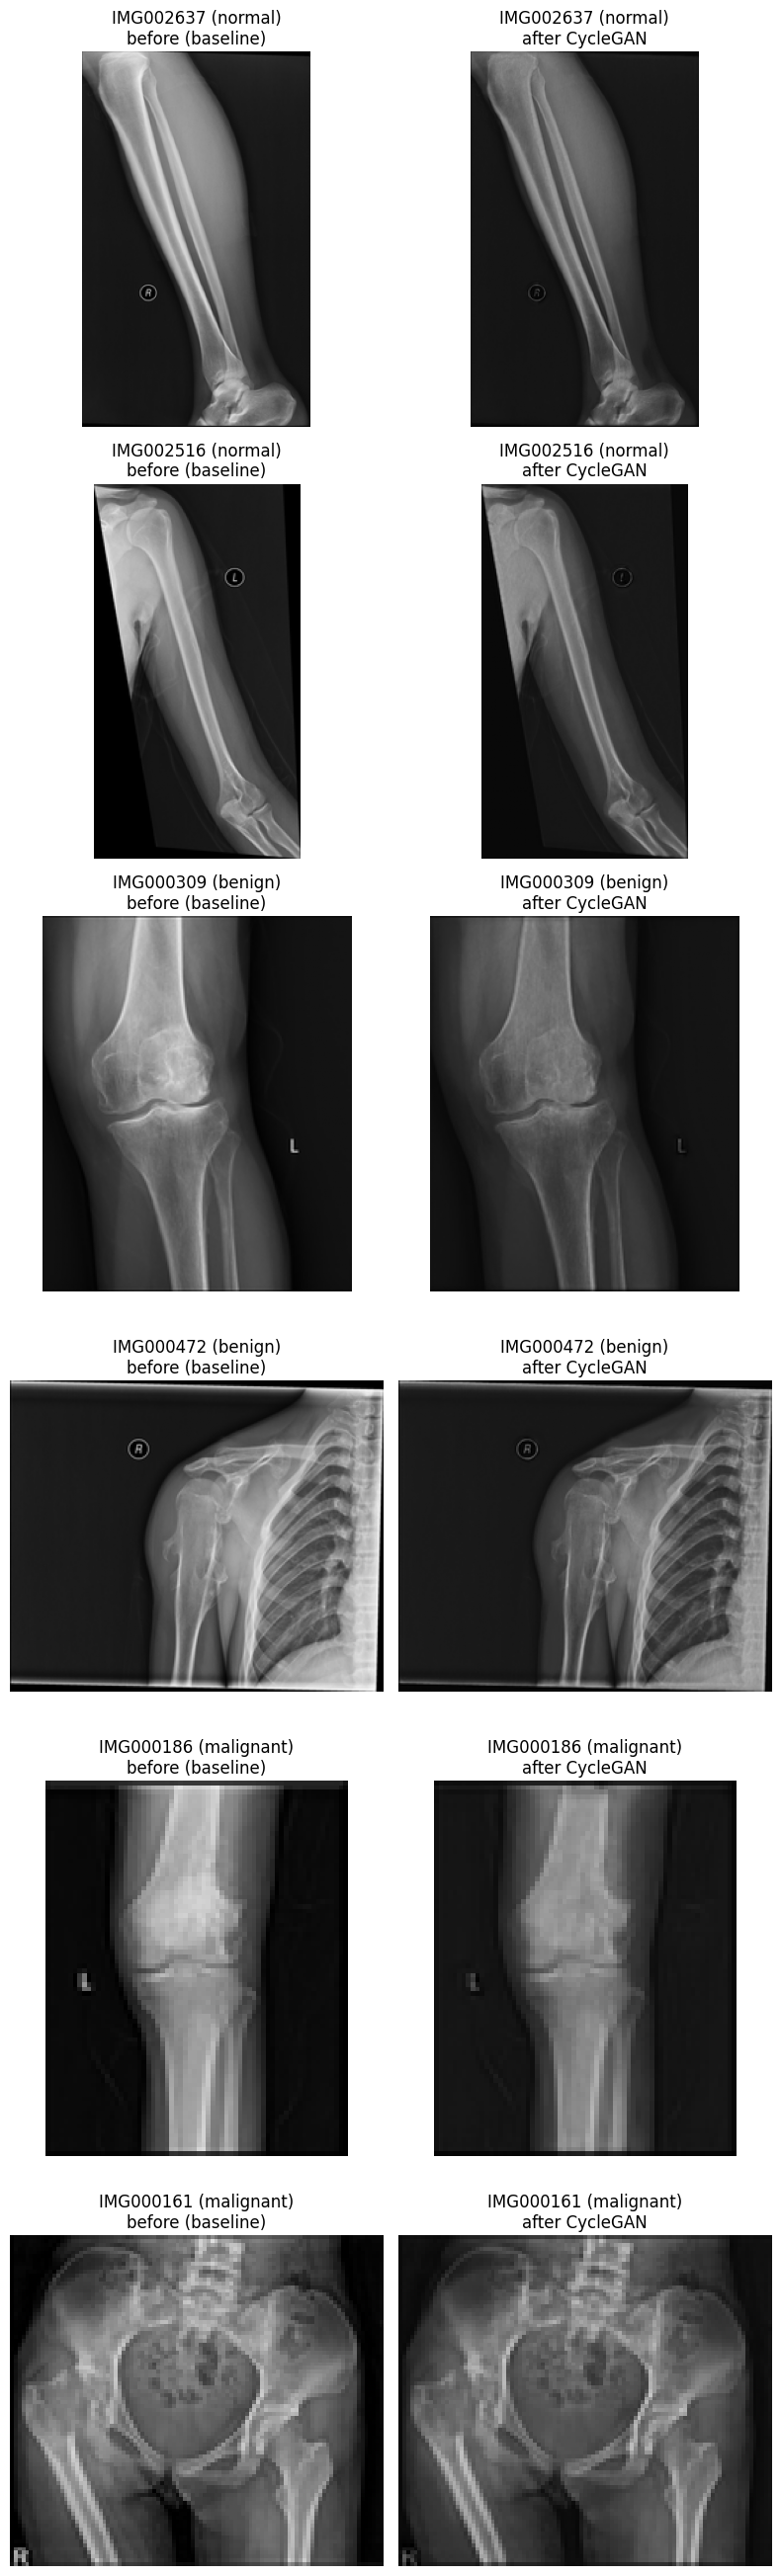

In [12]:
picks = pd.concat([images[images["group"] == group].sample(2, random_state=42)
                   for group in ["normal", "benign", "malignant"]])
titles = ["before (baseline)", "after CycleGAN"]

fig, axes = plt.subplots(len(picks), 2, figsize=(8, 4.4 * len(picks)))
for row, (_, pick) in zip(axes, picks.iterrows()):
    before = baseline(pick)                                    # the baseline image
    after = shrink(cyclegan(load(pick['path'])))               # CycleGAN on the full image, then 512 x 512
    top, bottom, left, right = xray_box(before)                # cut away the black square, so the bone is big enough to see
    for ax, picture, title in zip(row, [before, after], titles):
        ax.imshow(picture[top:bottom, left:right], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{pick['image']} ({pick['group']})\n{title}")
        ax.axis("off")

plt.tight_layout()
plt.show()

## Measuring functions
The same functions as in the classical notebooks.
- PSNR and SSIM: how much the image changed (higher = less change). Measured on the X-ray only, not the black square.
- CII: how much more the tumor stands out from the ring around it. Above 1 = it stands out more.

In [13]:
def tumor_mask(name):
    annotation = json.loads((ANNOTATIONS / (name + ".json")).read_text())
    scale = SIZE[0] / annotation["imageWidth"]                 # the outline was drawn on the 2440 x 2440 image
    mask = np.zeros((SIZE[1], SIZE[0]), dtype=np.uint8)
    for shape in annotation["shapes"]:
        if shape["shape_type"] == "polygon":                   # the outline (the rectangles are only boxes)
            points = np.round(np.array(shape["points"]) * scale).astype(np.int32)
            cv2.fillPoly(mask, [points], 1)
    return mask == 1                                           # True inside the tumor


def ring_around(tumor, before):
    kernel = np.ones((2 * RING + 1, 2 * RING + 1), dtype=np.uint8)
    bigger = cv2.dilate(tumor.astype(np.uint8), kernel) == 1   # the tumor made RING pixels bigger
    return bigger & ~tumor & (before > BLACK)                  # the ring: not the tumor, not the black background


def contrast(image, tumor, ring):
    t = image[tumor].mean()                                    # tumor brightness
    r = image[ring].mean()                                     # ring brightness
    return abs(t - r) / (t + r)                                # abs: a tumor can be darker or brighter than the bone


def cii(before, after, tumor, ring):
    if tumor.sum() == 0 or ring.sum() == 0:
        return np.nan                                          # cannot be measured
    contrast_before = contrast(before, tumor, ring)
    if contrast_before == 0:
        return np.nan                                          # cannot divide by 0
    return contrast(after, tumor, ring) / contrast_before


def psnr_ssim(before, after):
    top, bottom, left, right = xray_box(before)                # the X-ray only
    a, b = before[top:bottom, left:right], after[top:bottom, left:right]
    return peak_signal_noise_ratio(a, b, data_range=255), structural_similarity(a, b, data_range=255)

## Measuring functions at full size
The same tumor outline and ring, but on the 2440 x 2440 image: the outline is not made smaller, and the ring is 48 pixels wide (the same area as the 10-pixel ring at 512 x 512), as in the classical `*_full_size_scores` notebooks.

In [14]:
def tumor_mask_full(name, size):
    annotation = json.loads((ANNOTATIONS / (name + ".json")).read_text())
    scale = size[1] / annotation["imageWidth"]                 # 1.0: the outline was drawn on the 2440 x 2440 image
    mask = np.zeros(size, dtype=np.uint8)
    for shape in annotation["shapes"]:
        if shape["shape_type"] == "polygon":                   # the outline (the rectangles are only boxes)
            points = np.round(np.array(shape["points"]) * scale).astype(np.int32)
            cv2.fillPoly(mask, [points], 1)
    return mask == 1                                           # True inside the tumor


def ring_around_full(tumor, before):
    kernel = np.ones((2 * RING_FULL + 1, 2 * RING_FULL + 1), dtype=np.uint8)
    bigger = cv2.dilate(tumor.astype(np.uint8), kernel) == 1   # the tumor made RING_FULL pixels bigger
    return bigger & ~tumor & (before > BLACK)                  # the ring: not the tumor, not the black background

## Make every image
For every image: CycleGAN on the full image, then 512 x 512, then saved as PNG in the Drive folder `BTXRD/BTXRD_cyclegan_512`.
While the full-size result is there, its **full-size scores** are measured too (the full image after CycleGAN against the original full image) and saved as one line per image in `BTXRD/BTXRD_cyclegan_512_full_size_scores.csv`. So the method runs only once.
Images that are already done are skipped, so after a disconnect this continues where it stopped.

In [15]:
def png_path(item):
    return OUT_DIR / item["split"] / item["label"] / (item["image"] + ".png")


def scored_images():
    if not FULL_SCORES.exists():
        return set()
    return set(pd.read_csv(FULL_SCORES)["image"])             # images that already have their full-size scores


scored = scored_images()
todo = [item for _, item in images.iterrows() if not png_path(item).exists() or item["image"] not in scored]
print(len(images) - len(todo), "images already done,", len(todo), "to do")

start = time.time()
for n, item in enumerate(todo, start=1):
    raw = load(item["path"])                                   # the original X-ray at full size
    full = cyclegan(raw)                                       # CycleGAN on the full image (2440 x 2440)
    after = shrink(full)                                       # then 512 x 512

    psnr, ssim = psnr_ssim(raw, full)                          # full-size scores: the full image after the method vs the original
    row = {"image": item["image"], "label": item["label"], "PSNR": psnr, "SSIM": ssim, "CII": np.nan}
    if item["label"] == "tumor":
        tumor = tumor_mask_full(item["image"], raw.shape)
        row["CII"] = cii(raw, full, tumor, ring_around_full(tumor, raw))
    pd.DataFrame([row]).to_csv(FULL_SCORES, mode="a", header=not FULL_SCORES.exists(), index=False)   # one line per image, in Drive

    target = png_path(item)
    target.parent.mkdir(parents=True, exist_ok=True)
    temporary = target.with_suffix(".tmp")
    Image.fromarray(after).save(temporary, format="PNG")
    os.replace(temporary, target)                              # renamed only when complete, so a half-written image is never kept

    if n % 100 == 0 or n == len(todo):
        minutes_left = (time.time() - start) / n * (len(todo) - n) / 60
        print(f"{n} of {len(todo)} done, about {minutes_left:.0f} minutes left")

done = sum(1 for _, item in images.iterrows() if png_path(item).exists())
scored = scored_images()
print(done, "of", len(images), "images are in", OUT_DIR, "|", len(scored & set(images["image"])), "have full-size scores")
assert done == len(images) and set(images["image"]) <= scored, "not all images are done: run this cell again"

1849 images already done, 1874 to do
100 of 1874 done, about 17 minutes left
200 of 1874 done, about 21 minutes left
300 of 1874 done, about 21 minutes left
400 of 1874 done, about 21 minutes left
500 of 1874 done, about 19 minutes left
600 of 1874 done, about 17 minutes left
700 of 1874 done, about 14 minutes left
800 of 1874 done, about 13 minutes left
900 of 1874 done, about 12 minutes left
1000 of 1874 done, about 11 minutes left
1100 of 1874 done, about 10 minutes left
1200 of 1874 done, about 9 minutes left
1300 of 1874 done, about 7 minutes left
1400 of 1874 done, about 6 minutes left
1500 of 1874 done, about 5 minutes left
1600 of 1874 done, about 4 minutes left
1700 of 1874 done, about 2 minutes left
1800 of 1874 done, about 1 minutes left
1874 of 1874 done, about 0 minutes left
3723 of 3723 images are in /content/drive/MyDrive/BTXRD/BTXRD_cyclegan_512 | 3723 have full-size scores


## Make the zip
Puts all images in `BTXRD_cyclegan_512.zip` (`BTXRD_cyclegan_512/split/label/name.png`), the same layout as `BTXRD_512.zip`, and also copies it to Drive.

In [16]:
with zipfile.ZipFile(NEW_ZIP, "w") as new_zip:                 # "w": makes a new zip (an old one with the same name is replaced)
    for _, item in images.iterrows():
        source = OUT_DIR / item["split"] / item["label"] / (item["image"] + ".png")
        new_zip.write(source, f"{NAME}/{item['split']}/{item['label']}/{item['image']}.png")

shutil.copy(NEW_ZIP, DRIVE / NEW_ZIP.name)                     # also keep the zip in Google Drive
print(len(images), "images saved in", NEW_ZIP, "and in", DRIVE / NEW_ZIP.name)

3723 images saved in /content/BTXRD_cyclegan_512.zip and in /content/drive/MyDrive/BTXRD/BTXRD_cyclegan_512.zip


## Check the new zip
Counts the images in each folder, checks that all are 512 x 512 gray images, and that every image is in the same split and label as in `BTXRD_512.zip`.

In [17]:
with zipfile.ZipFile(NEW_ZIP) as new_zip:
    files = [name for name in new_zip.namelist() if name.endswith(".png")]
    sizes, modes = Counter(), Counter()
    for name in files:
        image = Image.open(new_zip.open(name))
        sizes[image.size] += 1
        modes[image.mode] += 1                                 # L = gray

for folder, count in sorted(Counter(name.rsplit("/", 1)[0] for name in files).items()):
    print(folder, count)
print("Sizes:", dict(sizes), "| modes:", dict(modes))
new_names = {name.removeprefix(NAME + "/").removesuffix(".png") for name in files}
print("Same images, split and label as BTXRD_512.zip:", new_names == old_names)
print("Zip size:", round(NEW_ZIP.stat().st_size / 1e6), "MB")

BTXRD_cyclegan_512/test/normal 280
BTXRD_cyclegan_512/test/tumor 279
BTXRD_cyclegan_512/train/normal 1306
BTXRD_cyclegan_512/train/tumor 1300
BTXRD_cyclegan_512/validation/normal 280
BTXRD_cyclegan_512/validation/tumor 278
Sizes: {(512, 512): 3723} | modes: {'L': 3723}
Same images, split and label as BTXRD_512.zip: True
Zip size: 63 MB


## Measure every image at 512 x 512
PSNR, SSIM and CII of every image in the new zip against its baseline image, as in the classical notebooks. CII is only for tumor images.

In [18]:
rows = []
with zipfile.ZipFile(NEW_ZIP) as new_zip:
    for _, item in images.iterrows():
        before = baseline(item)                                # the baseline image
        after = np.array(Image.open(io.BytesIO(new_zip.read(f"{NAME}/{item['split']}/{item['label']}/{item['image']}.png"))))

        psnr, ssim = psnr_ssim(before, after)
        row = {"image": item["image"], "label": item["label"], "PSNR": psnr, "SSIM": ssim, "CII": np.nan}
        if item["label"] == "tumor":
            tumor = tumor_mask(item["image"])
            row["CII"] = cii(before, after, tumor, ring_around(tumor, before))
        rows.append(row)

scores = pd.DataFrame(rows)
print(len(scores), "images measured")

3723 images measured


## Results at 512 x 512
The middle value (median) of each score: the image after CycleGAN compared with the baseline image. CII only counts the tumor images.

In [19]:
scores[["PSNR", "SSIM", "CII"]].median().round(3)

,0
PSNR,22.692
SSIM,0.917
CII,0.970


## Results at full size
The middle value (median) of each score at full size: the full image after CycleGAN compared with the original full image. CII only counts the tumor images.

In [20]:
full_scores = pd.read_csv(FULL_SCORES).drop_duplicates("image", keep="last")   # one line per image (a disconnect can repeat one)
full_scores = full_scores[full_scores["image"].isin(images["image"])]
print(len(full_scores), "images with full-size scores")
assert len(full_scores) == len(images)
full_scores[["PSNR", "SSIM", "CII"]].median().round(3)

3723 images with full-size scores


,0
PSNR,22.289
SSIM,0.824
CII,0.979


## Did the centers come closer?
The average brightness and spread of the X-ray pixels per center at 512 x 512, before and after. If it worked, the numbers of the 3 centers are closer together after CycleGAN than before.

In [21]:
rows = []
with zipfile.ZipFile(NEW_ZIP) as new_zip:
    for _, item in images.iterrows():
        before = baseline(item)                                # the baseline image
        after = np.array(Image.open(io.BytesIO(new_zip.read(f"{NAME}/{item['split']}/{item['label']}/{item['image']}.png"))))
        xray = before > BLACK                                  # the X-ray only, not the black square
        rows.append({"center": item["center"], "brightness before": before[xray].mean(), "brightness after": after[xray].mean(),
                     "spread before": before[xray].std(), "spread after": after[xray].std()})

pd.DataFrame(rows).groupby("center").mean().round(1)

,brightness before,brightness after,spread before,spread after
center,,,,
1,86.4,71.0,48.7,36.2
2,103.4,81.8,51.1,37.5
3,107.0,81.8,54.4,38.4


## Download the zip and the full-size scores

In [22]:
from google.colab import files                                 # imported again: the zip check above uses the name "files" for its list

files.download(str(NEW_ZIP))                                   # or download both from the Google Drive folder BTXRD
files.download(str(FULL_SCORES))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>